# Association Rules & Model Performance Metrics

Two topics in one notebook:
1. **Association rules:** finding items that often appear together (market-basket analysis).
2. **Evaluation metrics:** how to judge a classifier beyond plain accuracy.

## 1. Association rules with Apriori
Three measures for a rule A → B:
- **Support** = P(A and B): how often both appear together.
- **Confidence** = P(B | A): when A appears, how often B also appears.
- **Lift** = Confidence / P(B):
  - lift > 1 means A and B appear together more often than by chance.
  - lift = 1 means no relationship.
  - lift < 1 means they appear together less often than by chance.

Apriori first finds **frequent itemsets** (support ≥ 40% here), then builds rules from them that meet the confidence threshold.

In [ ]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Define the transaction dataset
dataset = [
    ['Bread', 'Butter'],
    ['Beer', 'Diaper', 'Bread'],
    ['Beer', 'Diaper', 'Milk'],
    ['Beer', 'Diaper', 'Bread', 'Butter'],
    ['Bread', 'Butter', 'Milk']
]

# 2. Convert transactions into a one-hot encoded DataFrame
te = TransactionEncoder()
te_ary = te.fit(dataset).transform(dataset)
df = pd.DataFrame(te_ary, columns=te.columns_)

print("--- One-Hot Encoded Dataset ---")
print(df)
print("\n")

# 3. Apply Apriori algorithm to find frequent itemsets (min_support = 0.4 or 2/5 transactions)
frequent_itemsets = apriori(df, min_support=0.4, use_colnames=True)

print("--- Frequent Itemsets (Support >= 40%) ---")
print(frequent_itemsets)
print("\n")

# 4. Generate association rules using confidence as the metric
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)

# 5. Filter specifically for the Beer -> Diaper rule
beer_diaper_rule = rules[
    (rules['antecedents'] == {'Beer'}) & (rules['consequents'] == {'Diaper'})
]

print("--- Association Rule: Beer -> Diaper ---")
print(beer_diaper_rule[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

--- One-Hot Encoded Dataset ---
    Beer  Bread  Butter  Diaper   Milk
0  False   True    True   False  False
1   True   True   False    True  False
2   True  False   False    True   True
3   True   True    True    True  False
4  False   True    True   False   True


--- Frequent Itemsets (Support >= 40%) ---
   support               itemsets
0      0.6                 (Beer)
1      0.8                (Bread)
2      0.6               (Butter)
3      0.6               (Diaper)
4      0.4                 (Milk)
5      0.4          (Beer, Bread)
6      0.6         (Beer, Diaper)
7      0.6        (Bread, Butter)
8      0.4        (Bread, Diaper)
9      0.4  (Beer, Bread, Diaper)


--- Association Rule: Beer -> Diaper ---
  antecedents consequents  support  confidence      lift
1      (Beer)    (Diaper)      0.6         1.0  1.666667


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Beer → Diaper:** support 0.6, confidence 1.0, lift 1.67. Every basket with beer also had diapers, and that's 1.67× more often than diapers appear overall.

In [ ]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Define the transaction dataset
dataset = [
    ['Bread', 'Butter'],
    ['Beer', 'Diaper', 'Bread'],
    ['Beer', 'Diaper', 'Milk'],
    ['Beer', 'Diaper', 'Bread', 'Butter'],
    ['Bread', 'Butter', 'Milk']
]

# 2. Convert transactions into a one-hot encoded DataFrame
te = TransactionEncoder()
te_ary = te.fit(dataset).transform(dataset)
df = pd.DataFrame(te_ary, columns=te.columns_)

# 3. Apply Apriori algorithm to find frequent itemsets
frequent_itemsets = apriori(df, min_support=0.4, use_colnames=True)

# 4. Generate association rules using confidence as the metric
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.6)

# 5. Filter for specific rules of interest
target_rules = rules[
    ((rules['antecedents'] == {'Beer'}) & (rules['consequents'] == {'Bread'})) |
    ((rules['antecedents'] == {'Bread'}) & (rules['consequents'] == {'Beer'})) |
    ((rules['antecedents'] == {'Butter'}) & (rules['consequents'] == {'Bread'})) |
    ((rules['antecedents'] == {'Bread'}) & (rules['consequents'] == {'Butter'})) |
    ((rules['antecedents'] == {'Diaper'}) & (rules['consequents'] == {'Bread'})) |
    ((rules['antecedents'] == {'Bread'}) & (rules['consequents'] == {'Diaper'})) |
    ((rules['antecedents'] == {'Beer'}) & (rules['consequents'] == {'Diaper'}))
]

print("--- Filtered Association Rules ---")
print(target_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

--- Filtered Association Rules ---
  antecedents consequents  support  confidence      lift
0      (Beer)     (Bread)      0.4    0.666667  0.833333
1      (Beer)    (Diaper)      0.6    1.000000  1.666667
3     (Bread)    (Butter)      0.6    0.750000  1.250000
4    (Butter)     (Bread)      0.6    1.000000  1.250000
5    (Diaper)     (Bread)      0.4    0.666667  0.833333


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Comparing rules:** Beer → Bread has confidence 0.67, but lift **0.83 < 1**. So a high confidence alone can be misleading, and lift shows they actually go together *less* often than by chance.

Association also doesn't mean one item causes the other.

## 2. Precision, Recall, F1 and Accuracy
Example: a disease test on 10,000 people.

| Metric | Formula | Question it answers |
|---|---|---|
| Precision | TP / (TP + FP) | Of those predicted sick, how many really are? |
| Recall | TP / (TP + FN) | Of those really sick, how many did we catch? |
| F1 | 2PR / (P + R) | Balance of precision and recall |
| Accuracy | (TP + TN) / all | Overall share correct |

In [1]:
# Confusion Matrix Counts
TP = 1000  # Sick diagnosed as Sick
FP = 800   # Healthy diagnosed as Sick
FN = 200   # Sick diagnosed as Healthy
TN = 8000  # Healthy diagnosed as Healthy

# Metrics Formulas
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1_score = 2 * (precision * recall) / (precision + recall)
accuracy = (TP + TN) / (TP + FP + FN + TN)

# Display Results
print(f"Precision : {precision:.4f} ({precision:.2%})")
print(f"Recall    : {recall:.4f} ({recall:.2%})")
print(f"F1-Score  : {f1_score:.4f} ({f1_score:.2%})")
print(f"Accuracy  : {accuracy:.4f} ({accuracy:.2%})")

Precision : 0.5556 (55.56%)
Recall    : 0.8333 (83.33%)
F1-Score  : 0.6667 (66.67%)
Accuracy  : 0.9000 (90.00%)


**Key insight:** accuracy is 90%, but precision is only 55.6%. Because most people are healthy, accuracy looks good even though nearly half of the "sick" predictions are wrong. With **imbalanced classes**, I should check precision, recall and F1.

In [2]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score

# Reconstruct ground truth (y_true) and predictions (y_pred) array
# Sick = 1, Healthy = 0
y_true = np.array([1] * 1200 + [0] * 8800)  # Total 1,200 Sick, 8,800 Healthy
y_pred = np.array(
    [1] * 1000 + [0] * 200 + [1] * 800 + [0] * 8000
)  # 1,000 TP, 200 FN, 800 FP, 8,000 TN

# 1. Individual Metric Functions
p = precision_score(y_true, y_pred, pos_label=1)
r = recall_score(y_true, y_pred, pos_label=1)
f1 = f1_score(y_true, y_pred, pos_label=1)

print(f"Precision : {p:.4f}")
print(f"Recall    : {r:.4f}")
print(f"F1-Score  : {f1:.4f}\n")

# 2. Confusion Matrix Verification
cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
# cm format: [[TP, FN], [FP, TN]] when labels=[1, 0]
print("Confusion Matrix:")
print(cm)

# 3. Comprehensive Classification Report
print("\nDetailed Classification Report:")
print(
    classification_report(
        y_true, y_pred, target_names=["Healthy (0)", "Sick (1)"], digits=4
    )
)

Precision : 0.5556
Recall    : 0.8333
F1-Score  : 0.6667

Confusion Matrix:
[[1000  200]
 [ 800 8000]]

Detailed Classification Report:
              precision    recall  f1-score   support

 Healthy (0)     0.9756    0.9091    0.9412      8800
    Sick (1)     0.5556    0.8333    0.6667      1200

    accuracy                         0.9000     10000
   macro avg     0.7656    0.8712    0.8039     10000
weighted avg     0.9252    0.9000    0.9082     10000



I rebuilt the labels as arrays and checked my manual results with scikit-learn. They match exactly. `classification_report` shows the metrics for both classes at once.

## 3. Comparing three classifiers on the student-support data
I calculated all four metrics for Logistic Regression, Decision Tree and KNN. KNN had the best recall and F1 for the "needs support" class. Recall matters most here, because missing a student who needs help is the worse mistake.

In [5]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# 1. Load dataset
df = pd.read_csv("/content/sample_data/student_data_support.csv")

# 2. Separate features and target
X = df.drop(columns=["student_id", "needs_support"])
y = (df["needs_support"] == "Yes").astype(int)  # 1 = Yes, 0 = No

# 3. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling (for Logistic Regression & KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Initialize Models
models = {
    "Logistic Regression": (
        LogisticRegression(random_state=42),
        X_train_scaled,
        X_test_scaled,
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=42, max_depth=5),
        X_train,
        X_test,
    ),
    "KNN (k=5)": (
        KNeighborsClassifier(n_neighbors=5),
        X_train_scaled,
        X_test_scaled,
    ),
}

# 6. Evaluate Models
results = []
for name, (model, train_x, test_x) in models.items():
  model.fit(train_x, y_train)
  y_pred = model.predict(test_x)

  results.append({
      "Model": name,
      "Precision": round(precision_score(y_test, y_pred), 4),
      "Recall": round(recall_score(y_test, y_pred), 4),
      "F1-Score": round(f1_score(y_test, y_pred), 4),
      "Accuracy": round(accuracy_score(y_test, y_pred), 4),
  })

# Display Results
results_df = pd.DataFrame(results)
print(results_df.to_string(index=True))

                 Model  Precision  Recall  F1-Score  Accuracy
0  Logistic Regression     0.6333  0.5588    0.5938      0.74
1        Decision Tree     0.5806  0.5294    0.5538      0.71
2            KNN (k=5)     0.6250  0.5882    0.6061      0.74


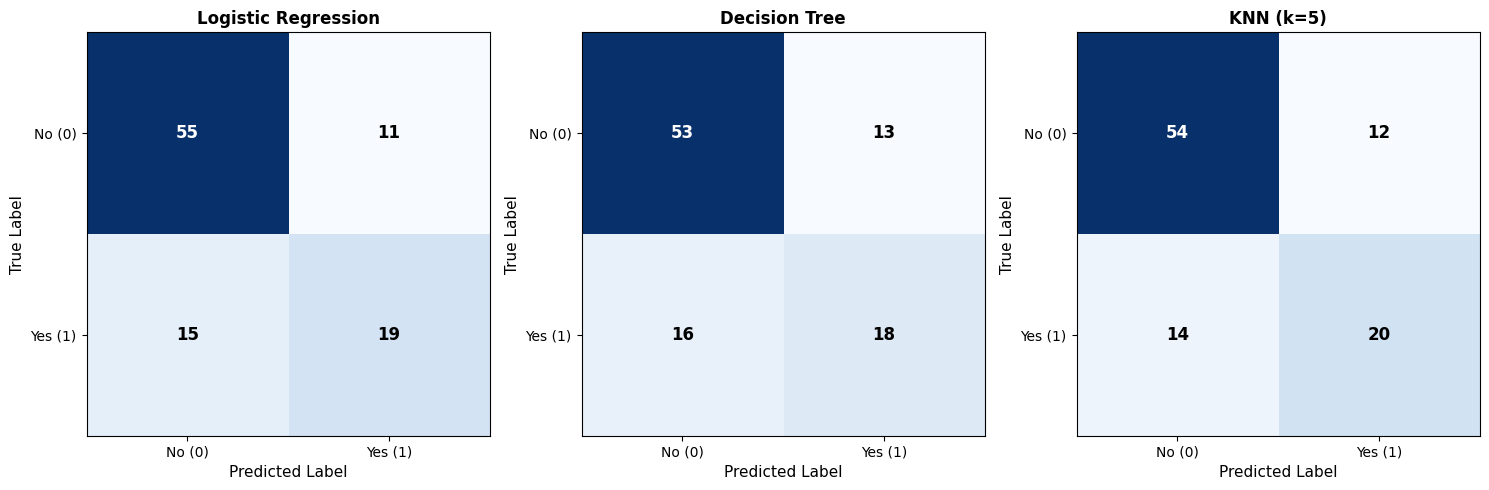

In [8]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

# Assuming 'models' and evaluation loop from your previous notebook cell:
model_names = ["Logistic Regression", "Decision Tree", "KNN (k=5)"]

# Set up a subplot grid (1 row, 3 columns) for easy side-by-side comparison
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for idx, (name, (model, train_x, test_x)) in enumerate(
    zip(model_names, models.values())
):
  # Predict on test set
  y_pred = model.predict(test_x)

  # Compute confusion matrix
  cm = confusion_matrix(y_test, y_pred)

  # Select subplot axis
  ax = axes[idx]

  # Plot matrix using imshow
  cax = ax.imshow(cm, cmap=plt.cm.Blues)

  # Labels & Title
  ax.set_xticks([0, 1])
  ax.set_yticks([0, 1])
  ax.set_xticklabels(["No (0)", "Yes (1)"], fontsize=10)
  ax.set_yticklabels(["No (0)", "Yes (1)"], fontsize=10)

  ax.set_xlabel("Predicted Label", fontsize=11)
  ax.set_ylabel("True Label", fontsize=11)
  ax.set_title(f"{name}", fontsize=12, fontweight="bold")

  # Annotate numbers inside the cells
  for i in range(2):
    for j in range(2):
      ax.text(
          j,
          i,
          str(cm[i, j]),
          ha="center",
          va="center",
          fontsize=12,
          fontweight="bold",
          color="white" if cm[i, j] > cm.max() / 2 else "black",
      )

# Adjust layout and show all three plots together
plt.tight_layout()
plt.show()

The confusion matrices show where each model goes wrong. The bottom-left cell (actual Yes, predicted No) is the number of students each model missed.

## 4. Hyperparameter tuning & cross-validation
Hyperparameters (like a tree's `max_depth` or KNN's `k`) are set **before** training. I compared different values using **5-fold cross-validation** on the training data only, so the test set stays a fair final check.

In [12]:
students = pd.read_csv('/content/sample_data/student_data_support.csv')

In [18]:
print( students.shape)
display(students.head())
display(students.describe())
classification_features = [
    "attendance",
    "previous_score",
    "study_hours",
    "lms_clicks",
    "assignment_completion"

]

X_cls = students[classification_features]
y_cls = students["needs_support"]

# Split before fitting any preprocessing or model.
# stratify=y_cls keeps a similar Yes/No proportion in both subsets.
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.25,
    stratify=y_cls,
    random_state=42,
)
print("Traning data:", X_train_cls.shape)
print("Test data:", X_test_cls.shape)
print("Training target proportions:")
display(y_train_cls.value_counts(normalize=True).round(3))

(500, 8)


,student_id,attendance,previous_score,study_hours,lms_clicks,assignment_completion,needs_support,final_score
0,S0001,81.7,87.1,4.9,33,75.2,No,74.6
1,S0002,65.5,80.5,3.4,31,72.0,Yes,65.0
2,S0003,87.0,57.9,4.1,74,88.5,Yes,68.3
3,S0004,89.3,47.0,6.4,52,85.8,No,63.2
4,S0005,54.6,26.5,5.0,40,60.9,Yes,45.5


,attendance,previous_score,study_hours,lms_clicks,assignment_completion,final_score
count,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000
mean,77.700200,67.35300,5.001200,41.744000,81.084200,64.717800
std,11.188189,14.10232,2.217113,21.591917,13.693888,8.780778
min,47.200000,25.00000,0.000000,0.000000,36.000000,39.400000
25%,69.975000,57.82500,3.500000,27.750000,71.575000,58.900000
50%,78.050000,68.15000,5.000000,42.000000,82.550000,65.000000
75%,85.025000,76.37500,6.400000,56.000000,91.900000,70.600000
max,100.000000,100.00000,11.200000,109.000000,100.000000,95.500000


Traning data: (375, 5)
Test data: (125, 5)
Training target proportions:


,proportion
needs_support,
No,0.661
Yes,0.339


,max_depth,training_accuracy,test_accuracy,mean_cv_accuracy
0,1,0.763,0.664,0.755
1,2,0.795,0.680,0.752
2,3,0.856,0.768,0.792
3,4,0.880,0.768,0.773
4,5,0.909,0.752,0.781
5,8,0.989,0.744,0.744
6,12,1.000,0.736,0.763
7,None,1.000,0.736,0.763


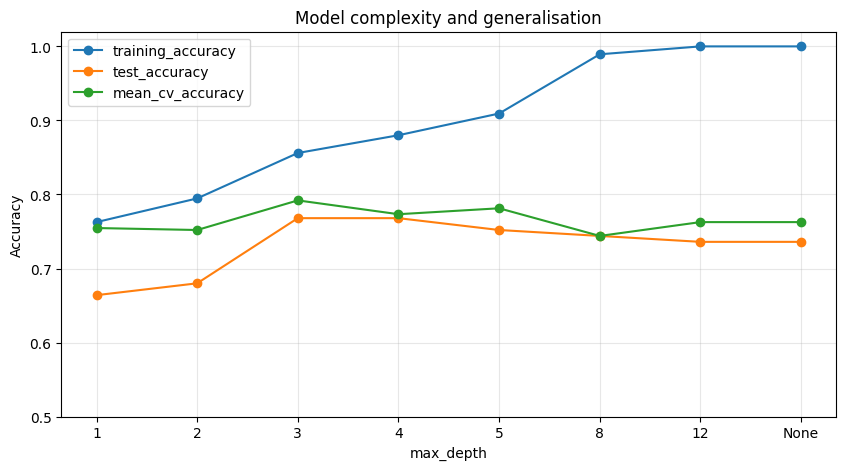

In [14]:
from sklearn.model_selection import cross_val_score
depth_results = []

for depth in [1, 2, 3, 4, 5, 8, 12, None]:
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=42)
    candidate.fit(X_train_cls, y_train_cls)

    train_acc = candidate.score(X_train_cls, y_train_cls)
    test_acc = candidate.score(X_test_cls, y_test_cls)

    # 1. Compute 5-fold cross-validation and take the mean score
    cv_scores = cross_val_score(candidate, X_train_cls, y_train_cls, cv=5)
    cv_acc = cv_scores.mean()


    depth_results.append({
        "max_depth": "None" if depth is None else str(depth),
        "training_accuracy": train_acc,
        "test_accuracy": test_acc,
        "mean_cv_accuracy": cv_acc,
    })

depth_table = pd.DataFrame(depth_results)
display(depth_table.round(3))

depth_table.plot(
    x="max_depth",
    y=["training_accuracy", "test_accuracy", "mean_cv_accuracy"],
    marker="o",
    figsize=(10, 5),
)
plt.ylim(0.5, 1.02)
plt.ylabel("Accuracy")
plt.title("Model complexity and generalisation")
plt.grid(alpha=0.3)
plt.show()

**Result:** depth 3 gave the best mean CV accuracy (0.792). Deeper trees reach 100% training accuracy but get worse on new data (overfitting).

## 5. KNN and tuning k
For KNN, I put `StandardScaler` inside a Pipeline so the scaling is redone inside each CV fold. That prevents information leaking from the validation fold.

In [15]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = pd.DataFrame({
    "attendance": [92, 68, 81, 74, 88, 63, 95, 71, 84, 66],
    "previous_score": [78, 55, 70, 60, 82, 50, 90, 58, 75, 52],
    "lms_clicks": [40, 12, 28, 18, 38, 9, 45, 15, 32, 10]
})
y = ["No", "Yes", "No", "Yes", "No",
     "Yes", "No", "Yes", "No", "Yes"]

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)
model.fit(X, y)

new_student = pd.DataFrame({
    "attendance": [70],
    "previous_score": [57],
    "lms_clicks": [14]
})

prediction = model.predict(new_student)[0]
print("Needs support:", prediction)

Needs support: Yes


In [16]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
# Tune k using cross-validation on the training set.
# The pipeline prevents scaling leakage inside every validation fold.
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid={"knn__n_neighbors": list(range(1, 22, 2))},
    scoring="accuracy",
    cv=5,
)
knn_search.fit(X_train_cls, y_train_cls)

best_knn = knn_search.best_estimator_
knn_train_accuracy = best_knn.score(X_train_cls, y_train_cls)
knn_test_accuracy = best_knn.score(X_test_cls, y_test_cls)

print("Best k:", knn_search.best_params_["knn__n_neighbors"])
print(f"Best mean validation accuracy: {knn_search.best_score_:.3f}")
print(f"KNN training accuracy:         {knn_train_accuracy:.3f}")
print(f"KNN test accuracy:             {knn_test_accuracy:.3f}")

Best k: 19
Best mean validation accuracy: 0.797
KNN training accuracy:         0.816
KNN test accuracy:             0.760


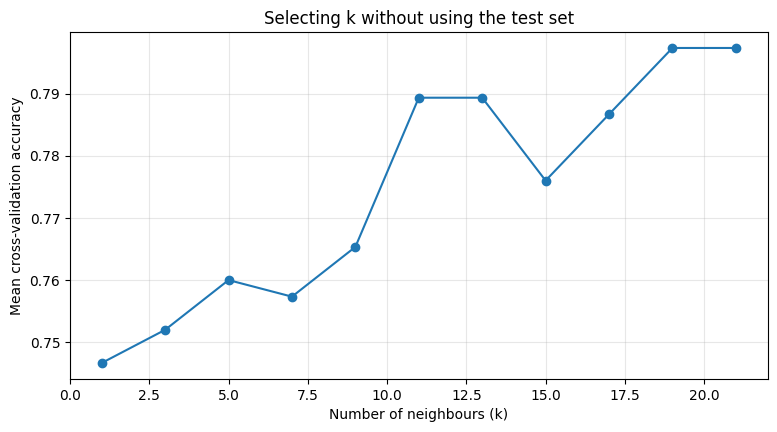

In [17]:
# Visualize how the choice of k affects validation accuracy.
knn_cv_results = pd.DataFrame(knn_search.cv_results_)

plt.figure(figsize=(9, 4.5))
plt.plot(
    knn_cv_results["param_knn__n_neighbors"].astype(int),
    knn_cv_results["mean_test_score"],
    marker="o",
)
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Mean cross-validation accuracy")
plt.title("Selecting k without using the test set")
plt.grid(alpha=0.3)
plt.show()

## What I learned
- **Lift** is the most useful rule measure. Confidence alone can mislead.
- **Accuracy** can hide poor performance on imbalanced data, so I should look at precision, recall and F1.
- Pick the metric based on which mistake is costlier. Missing a student who needs help (FN) is usually worse than a false alert, so recall is important.
- Tune hyperparameters with cross-validation on the training set.